In [1]:
import numpy as np

import tensorflow as tf
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.activations import relu, linear, leaky_relu

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt

np.set_printoptions(precision=2)
tf.get_logger().setLevel('ERROR')
tf.autograph.set_verbosity(0)

In [2]:
def build_models():
    model_1 = Sequential(
        [
            Dense(25, activation='relu'),
            Dense(15, activation='relu'),
            Dense(1, activation='linear')
        ], name='model_1'
    )
    model_2 = Sequential(
        [
            Dense(20, activation='relu'),
            Dense(12, activation='relu'),
            Dense(12, activation='relu'),
            Dense(20, activation='relu'),
            Dense(1, activation='linear'),
        ], name='model_2'
    )
    model_3 = Sequential(
        [
            Dense(32, activation='relu'),
            Dense(16, activation='relu'),
            Dense(8, activation='relu'),
            Dense(4, activation='relu'),
            Dense(12, activation='relu'),
            Dense(1, activation='linear'),
        ], name='model_3'
    )

    return [model_1, model_2, model_3]

In [3]:
data = np.loadtxt('data_w3_ex1.csv', delimiter=',')
x = data[:,:-1]
y = data[:,-1]
x = x.reshape(-1,1)
y = y.reshape(-1,1)
print(x.shape, y.shape)

(50, 1) (50, 1)


In [4]:
x_train, x_, y_train, y_ = train_test_split(x, y, test_size=0.4, random_state=1)
x_cv, x_test, y_cv, y_test = train_test_split(x_, y_, test_size=0.5, random_state=1)
print(f"x_train.shape: {x_train.shape}")
print(f"x_cv.shape: {x_cv.shape}")
print(f"x_test.shape: {x_test.shape}")
print(f"y_train.shape: {y_train.shape}")
print(f"y_cv.shape: {y_cv.shape}")
print(f"y_test.shape: {y_test.shape}")

x_train.shape: (30, 1)
x_cv.shape: (10, 1)
x_test.shape: (10, 1)
y_train.shape: (30, 1)
y_cv.shape: (10, 1)
y_test.shape: (10, 1)


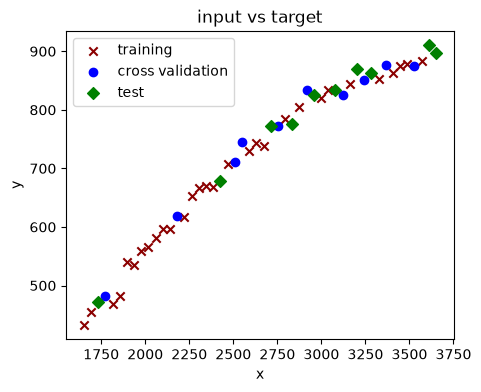

In [5]:
fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(x_train, y_train, c='darkred', marker='x', label='training')
ax.scatter(x_cv, y_cv, c='b', marker='o', label='cross validation')
ax.scatter(x_test, y_test, c='g', marker='D', label='test')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('input vs target')
ax.legend()
plt.show()

In [6]:
# add polynomial features (there's no need in neural networks because they can learn non-linear relations)
degree = 1 # so we're putting degree of 1 input will remain the same
poly = PolynomialFeatures(degree, include_bias=False)

X_train_mapped = poly.fit_transform(x_train)
X_cv_mapped = poly.transform(x_cv)
X_test_mapped = poly.transform(x_test)

In [7]:
# as we can see below
np.array_equal(x_train, X_train_mapped)

True

In [8]:
# scale our input
scaler = StandardScaler()
X_train_mapped_scaled = scaler.fit_transform(X_train_mapped)
X_cv_mapped_scaled = scaler.transform(X_cv_mapped)
X_test_mapped_scaled = scaler.transform(X_test_mapped)

In [9]:
# build and train the models

tf.random.set_seed(1)

nn_train_mses = []
nn_cv_mses = []

nn_models = build_models()

for model in nn_models:

    model.compile(
        loss = 'mse',
        optimizer = tf.keras.optimizers.Adam(0.1)
    )

    print(f"Training {model.name}...")

    model.fit(
        X_train_mapped_scaled, y_train,
        epochs=50,
        verbose=0
    )

    print("Done!\n")

    yhat = model.predict(X_train_mapped_scaled, verbose=0)
    train_mse = mean_squared_error(y_train, yhat) / 2
    nn_train_mses.append(train_mse)

    yhat = model.predict(X_cv_mapped_scaled, verbose=0)
    cv_mse = mean_squared_error(y_cv, yhat) / 2
    nn_cv_mses.append(cv_mse)

print('RESULTS!!')
for model_num in range(len(nn_train_mses)):
    print(
        f"Model {model_num+1}: Training MSE: {nn_train_mses[model_num]:.2f},",
        f"CV MSE: {nn_cv_mses[model_num]:.2f}"
    )

Training model_1...
Done!

Training model_2...
Done!

Training model_3...
Done!

RESULTS!!
Model 1: Training MSE: 2520.86, CV MSE: 2735.74
Model 2: Training MSE: 1005.99, CV MSE: 1171.20
Model 3: Training MSE: 662.48, CV MSE: 795.83
